# Proyecto Final - Fundamentos de Redes Neuronales
## Predicción de la intención de compra en sesiones de comercio electrónico

**Integrantes:** Ángel Santiago Díaz Toloza y Juan Mateo Jaramillo Guerra  
**Dataset:** Online Shoppers Purchasing Intention - UCI  
**Variable objetivo:** `Revenue`



## 1. Instalación e importaciones

In [1]:
!pip -q install ucimlrepo

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    auc,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED_SPLIT = 17
SEMILLAS_ESTABILIDAD = [17, 31, 53]

np.random.seed(SEED_SPLIT)
tf.keras.utils.set_random_seed(SEED_SPLIT)

print("TensorFlow:", tf.__version__)
print("Semilla del split:", SEED_SPLIT)
print("Semillas de estabilidad:", SEMILLAS_ESTABILIDAD)

TensorFlow: 2.21.0
Semilla del split: 17
Semillas de estabilidad: [17, 31, 53]


## 2. Carga del dataset

In [3]:
datos_uci = fetch_ucirepo(id=468)

X = datos_uci.data.features.copy()
y = datos_uci.data.targets.copy()

df = pd.concat([X, y], axis=1)

if df["Revenue"].dtype == bool:
    df["Revenue_num"] = df["Revenue"].astype(int)
else:
    df["Revenue_num"] = (
        df["Revenue"]
        .astype(str)
        .str.upper()
        .map({"TRUE": 1, "FALSE": 0})
    )

print("Forma original:", df.shape)
display(df.head())

Forma original: (12330, 19)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Revenue_num
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False,0


## 3. Auditoría de calidad

In [4]:
columnas_originales = [c for c in df.columns if c != "Revenue_num"]

print("Registros:", len(df))
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Duplicados exactos:", int(df.duplicated(subset=columnas_originales).sum()))

balance = (
    df["Revenue_num"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Sin compra", 1: "Compra"})
)

print("\nDistribución de Revenue:")
display(pd.DataFrame({
    "Sesiones": balance,
    "Porcentaje": (balance / balance.sum() * 100).round(2)
}))

Registros: 12330
Valores faltantes: 0
Duplicados exactos: 125

Distribución de Revenue:


,Sesiones,Porcentaje
Revenue_num,,
Sin compra,10422,84.53
Compra,1908,15.47


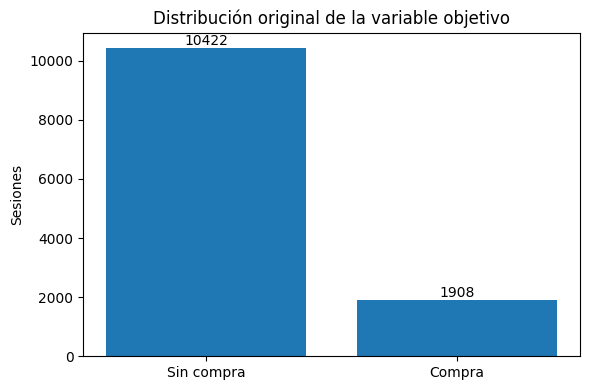

In [5]:
plt.figure(figsize=(6, 4))
plt.bar(balance.index, balance.values)
plt.ylabel("Sesiones")
plt.title("Distribución original de la variable objetivo")

for i, valor in enumerate(balance.values):
    plt.text(i, valor + 100, str(valor), ha="center")

plt.tight_layout()
plt.show()

## 4. Eliminación de duplicados y partición

Los duplicados exactos se retiran antes de dividir los datos.  
La partición se mantiene estratificada en 70 % entrenamiento, 15 % validación y 15 % prueba.

In [6]:
df_modelo = (
    df
    .drop_duplicates(subset=columnas_originales)
    .copy()
)

train_df, temporal_df = train_test_split(
    df_modelo,
    test_size=0.30,
    stratify=df_modelo["Revenue_num"],
    random_state=SEED_SPLIT
)

val_df, test_df = train_test_split(
    temporal_df,
    test_size=0.50,
    stratify=temporal_df["Revenue_num"],
    random_state=SEED_SPLIT
)

resumen_split = pd.DataFrame({
    "Conjunto": ["Train", "Validación", "Prueba"],
    "Filas": [len(train_df), len(val_df), len(test_df)],
    "% compra": [
        train_df["Revenue_num"].mean() * 100,
        val_df["Revenue_num"].mean() * 100,
        test_df["Revenue_num"].mean() * 100
    ]
})

print("Filas después de retirar duplicados:", len(df_modelo))
display(resumen_split.round(2))

Filas después de retirar duplicados: 12205


,Conjunto,Filas,% compra
0,Train,8543,15.64
1,Validación,1831,15.62
2,Prueba,1831,15.62


## 5. Interacción ProductRelated_Duration × ExitRates

In [7]:
mediana_duracion = df_modelo["ProductRelated_Duration"].median()
mediana_exit = df_modelo["ExitRates"].median()

interaccion = df_modelo.copy()

interaccion["Duracion_grupo"] = np.where(
    interaccion["ProductRelated_Duration"] >= mediana_duracion,
    "Alta",
    "Baja"
)

interaccion["Exit_grupo"] = np.where(
    interaccion["ExitRates"] >= mediana_exit,
    "Alta",
    "Baja"
)

tabla_interaccion = (
    interaccion
    .groupby(["Duracion_grupo", "Exit_grupo"])
    .agg(
        Sesiones=("Revenue_num", "size"),
        Tasa_compra=("Revenue_num", "mean")
    )
    .reset_index()
)

tabla_interaccion["Tasa_compra"] *= 100
display(tabla_interaccion.round(2))

,Duracion_grupo,Exit_grupo,Sesiones,Tasa_compra
0,Alta,Alta,2209,12.18
1,Alta,Baja,3894,28.04
2,Baja,Alta,4075,5.52
3,Baja,Baja,2027,15.89


## 6. Preparación de variables

In [8]:
categorias = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

categorias_con_raras = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

variables_log = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration"
]

numericas_estandar = [
    "BounceRates",
    "ExitRates",
    "SpecialDay"
]

mapa_raras = {}

for columna in categorias_con_raras:
    serie = train_df[columna].astype(str)
    frecuencias = serie.value_counts(normalize=True)
    mapa_raras[columna] = frecuencias[
        frecuencias < 0.01
    ].index.tolist()

def preparar_categorias(datos):
    salida = datos.copy()

    for columna in categorias:
        salida[columna] = salida[columna].astype(str)

    for columna, niveles_raros in mapa_raras.items():
        salida[columna] = salida[columna].where(
            ~salida[columna].isin(niveles_raros),
            "OTRA"
        )

    return salida

train_prep = preparar_categorias(train_df)
val_prep = preparar_categorias(val_df)
test_prep = preparar_categorias(test_df)

print("Categorías raras agrupadas usando únicamente entrenamiento:")
for columna, niveles in mapa_raras.items():
    print(columna, "->", niveles)

Categorías raras agrupadas usando únicamente entrenamiento:
OperatingSystems -> ['8', '6', '5', '7']
Browser -> ['3', '13', '7', '12', '11', '9']
Region -> []
TrafficType -> ['15', '9', '7', '19', '14', '18', '16', '12']


In [9]:
def one_hot_compatible():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

def construir_preprocesador(incluir_pagevalues=False):
    numericas = numericas_estandar.copy()

    if incluir_pagevalues:
        numericas = numericas + ["PageValues"]

    return ColumnTransformer([
        (
            "log",
            Pipeline([
                ("log1p", FunctionTransformer(np.log1p, validate=False)),
                ("scale", StandardScaler())
            ]),
            variables_log
        ),
        (
            "num",
            StandardScaler(),
            numericas
        ),
        (
            "cat",
            one_hot_compatible(),
            categorias
        )
    ])

## 7. Comparación del baseline logístico con y sin PageValues

In [10]:
columnas_sin_pv = [
    c for c in train_prep.columns
    if c not in ["Revenue", "Revenue_num", "PageValues"]
]

columnas_con_pv = [
    c for c in train_prep.columns
    if c not in ["Revenue", "Revenue_num"]
]

prep_sin_pv = construir_preprocesador(
    incluir_pagevalues=False
)

prep_con_pv = construir_preprocesador(
    incluir_pagevalues=True
)

X_train_sin_pv = prep_sin_pv.fit_transform(
    train_prep[columnas_sin_pv]
).astype("float32")

X_val_sin_pv = prep_sin_pv.transform(
    val_prep[columnas_sin_pv]
).astype("float32")

X_test_sin_pv = prep_sin_pv.transform(
    test_prep[columnas_sin_pv]
).astype("float32")

X_train_con_pv = prep_con_pv.fit_transform(
    train_prep[columnas_con_pv]
).astype("float32")

X_val_con_pv = prep_con_pv.transform(
    val_prep[columnas_con_pv]
).astype("float32")

y_train = train_prep["Revenue_num"].to_numpy(dtype="float32")
y_val = val_prep["Revenue_num"].to_numpy(dtype="float32")
y_test = test_prep["Revenue_num"].to_numpy(dtype="float32")

print("Entrada sin PageValues:", X_train_sin_pv.shape)
print("Entrada con PageValues:", X_train_con_pv.shape)

Entrada sin PageValues: (8543, 58)
Entrada con PageValues: (8543, 59)


In [11]:
def calcular_metricas(y_real, probabilidades, umbral=0.5):
    pred = (probabilidades >= umbral).astype(int)

    precision_curve, recall_curve, _ = precision_recall_curve(
        y_real,
        probabilidades
    )

    return {
        "Accuracy": accuracy_score(y_real, pred),
        "Precision": precision_score(
            y_real,
            pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_real,
            pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_real,
            pred,
            zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_real,
            probabilidades
        ),
        "PR_AUC": auc(
            recall_curve,
            precision_curve
        )
    }

In [12]:
logistica_sin_pv = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED_SPLIT
)

logistica_con_pv = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED_SPLIT
)

logistica_sin_pv.fit(
    X_train_sin_pv,
    y_train.astype(int)
)

logistica_con_pv.fit(
    X_train_con_pv,
    y_train.astype(int)
)

prob_log_sin_val = logistica_sin_pv.predict_proba(
    X_val_sin_pv
)[:, 1]

prob_log_con_val = logistica_con_pv.predict_proba(
    X_val_con_pv
)[:, 1]

metricas_log_sin_val = calcular_metricas(
    y_val.astype(int),
    prob_log_sin_val
)

metricas_log_con_val = calcular_metricas(
    y_val.astype(int),
    prob_log_con_val
)

comparacion_pagevalues = pd.DataFrame([
    {
        "Modelo": "Logística sin PageValues",
        **metricas_log_sin_val
    },
    {
        "Modelo": "Logística con PageValues",
        **metricas_log_con_val
    }
])

display(comparacion_pagevalues.round(4))

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logística sin PageValues,0.6494,0.2652,0.7028,0.3851,0.7458,0.3361
1,Logística con PageValues,0.8433,0.4988,0.7378,0.5952,0.8914,0.6284


`PageValues` se mantiene fuera del modelo neuronal final. La comparación anterior sirve para mostrar cuánto cambia la señal disponible, pero no se incorpora mientras no esté garantizado que la variable exista antes de conocer el resultado de compra.

## 8. Datos definitivos para la red neuronal

In [13]:
X_train = X_train_sin_pv
X_val = X_val_sin_pv
X_test = X_test_sin_pv
preprocesador_final = prep_sin_pv
columnas_modelo = columnas_sin_pv

conteos = np.bincount(
    y_train.astype(int)
)

total = conteos.sum()

pesos_clase = {
    0: total / (2 * conteos[0]),
    1: total / (2 * conteos[1])
}

print("Dimensiones finales:")
print("Train:", X_train.shape)
print("Val:", X_val.shape)
print("Test:", X_test.shape)
print("Pesos de clase:", pesos_clase)

Dimensiones finales:
Train: (8543, 58)
Val: (1831, 58)
Test: (1831, 58)
Pesos de clase: {0: np.float64(0.5926876647703622), 1: np.float64(3.1972305389221556)}


## 9. Modelo neuronal base

In [14]:
def crear_modelo_base():
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(
            shape=(X_train.shape[1],)
        ),
        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),
        tf.keras.layers.Dense(
            16,
            activation="relu"
        ),
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.Precision(
                name="precision"
            ),
            tf.keras.metrics.Recall(
                name="recall"
            ),
            tf.keras.metrics.AUC(
                name="roc_auc"
            ),
            tf.keras.metrics.AUC(
                curve="PR",
                name="pr_auc"
            )
        ]
    )

    return modelo

In [15]:
tf.keras.backend.clear_session()
np.random.seed(SEED_SPLIT)
tf.keras.utils.set_random_seed(SEED_SPLIT)

modelo_base = crear_modelo_base()

early_base = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=10,
    min_delta=1e-4,
    restore_best_weights=True
)

hist_base = modelo_base.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    class_weight=pesos_clase,
    callbacks=[early_base],
    verbose=0
)

prob_base_val = modelo_base.predict(
    X_val,
    verbose=0
).ravel()

metricas_base_val = calcular_metricas(
    y_val.astype(int),
    prob_base_val
)

print("Mejor época base:",
      int(np.argmax(hist_base.history["val_pr_auc"]) + 1))

display(
    pd.DataFrame(
        [metricas_base_val],
        index=["Red base 32-16"]
    ).round(4)
)

Mejor época base: 15


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Red base 32-16,0.6963,0.2997,0.7063,0.4208,0.7733,0.3582


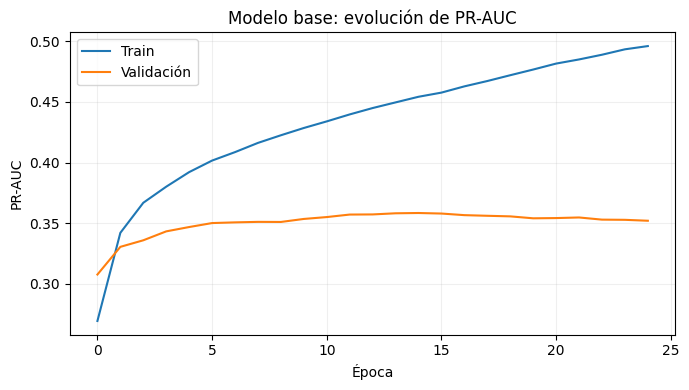

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(
    hist_base.history["pr_auc"],
    label="Train"
)
plt.plot(
    hist_base.history["val_pr_auc"],
    label="Validación"
)
plt.xlabel("Época")
plt.ylabel("PR-AUC")
plt.title("Modelo base: evolución de PR-AUC")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Modelo neuronal final

In [17]:
def crear_modelo_final():
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(
            shape=(X_train.shape[1],)
        ),
        tf.keras.layers.Dense(
            64,
            activation="relu"
        ),
        tf.keras.layers.Dropout(0.15),
        tf.keras.layers.Dense(
            32,
            activation="relu"
        ),
        tf.keras.layers.Dropout(0.15),
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.Precision(
                name="precision"
            ),
            tf.keras.metrics.Recall(
                name="recall"
            ),
            tf.keras.metrics.AUC(
                name="roc_auc"
            ),
            tf.keras.metrics.AUC(
                curve="PR",
                name="pr_auc"
            )
        ]
    )

    return modelo

In [18]:
tf.keras.backend.clear_session()
np.random.seed(SEED_SPLIT)
tf.keras.utils.set_random_seed(SEED_SPLIT)

modelo_final = crear_modelo_final()

early_final = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=8,
    min_delta=1e-4,
    restore_best_weights=True
)

hist_final = modelo_final.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=80,
    batch_size=32,
    class_weight=pesos_clase,
    callbacks=[early_final],
    verbose=0
)

prob_final_val = modelo_final.predict(
    X_val,
    verbose=0
).ravel()

metricas_final_val = calcular_metricas(
    y_val.astype(int),
    prob_final_val
)

print("Mejor época final:",
      int(np.argmax(hist_final.history["val_pr_auc"]) + 1))

display(
    pd.DataFrame(
        [metricas_final_val],
        index=["Red final 64-32 + Dropout"]
    ).round(4)
)

Mejor época final: 18


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Red final 64-32 + Dropout,0.6947,0.2966,0.6958,0.4159,0.776,0.3861


In [19]:
comparacion_validacion = pd.DataFrame([
    {
        "Modelo": "Logística",
        **metricas_log_sin_val
    },
    {
        "Modelo": "Red base 32-16",
        **metricas_base_val
    },
    {
        "Modelo": "Red final 64-32 + Dropout",
        **metricas_final_val
    }
])

display(comparacion_validacion.round(4))

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logística,0.6494,0.2652,0.7028,0.3851,0.7458,0.3361
1,Red base 32-16,0.6963,0.2997,0.7063,0.4208,0.7733,0.3582
2,Red final 64-32 + Dropout,0.6947,0.2966,0.6958,0.4159,0.7760,0.3861


## 11. Validación de estabilidad con varias semillas

In [20]:
def entrenar_final_con_semilla(semilla):
    tf.keras.backend.clear_session()
    np.random.seed(semilla)
    tf.keras.utils.set_random_seed(semilla)

    modelo = crear_modelo_final()

    early = tf.keras.callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=8,
        min_delta=1e-4,
        restore_best_weights=True
    )

    historial = modelo.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=80,
        batch_size=32,
        class_weight=pesos_clase,
        callbacks=[early],
        verbose=0
    )

    prob_train = modelo.predict(
        X_train,
        verbose=0
    ).ravel()

    prob_val = modelo.predict(
        X_val,
        verbose=0
    ).ravel()

    met_train = calcular_metricas(
        y_train.astype(int),
        prob_train
    )

    met_val = calcular_metricas(
        y_val.astype(int),
        prob_val
    )

    return {
        "Semilla": semilla,
        "PR_AUC_train": met_train["PR_AUC"],
        "PR_AUC_val": met_val["PR_AUC"],
        "Brecha_PR_AUC": (
            met_train["PR_AUC"]
            - met_val["PR_AUC"]
        ),
        "Precision_val": met_val["Precision"],
        "Recall_val": met_val["Recall"],
        "F1_val": met_val["F1"],
        "ROC_AUC_val": met_val["ROC_AUC"],
        "Mejor_epoca": int(
            np.argmax(
                historial.history["val_pr_auc"]
            ) + 1
        )
    }

In [21]:
resultados_estabilidad = []

for semilla in SEMILLAS_ESTABILIDAD:
    resultado = entrenar_final_con_semilla(
        semilla
    )
    resultados_estabilidad.append(
        resultado
    )

tabla_estabilidad = pd.DataFrame(
    resultados_estabilidad
)

display(tabla_estabilidad.round(4))

resumen_estabilidad = pd.DataFrame({
    "Métrica": [
        "PR-AUC validación",
        "Brecha train-val",
        "F1 validación",
        "Recall validación"
    ],
    "Media": [
        tabla_estabilidad["PR_AUC_val"].mean(),
        tabla_estabilidad["Brecha_PR_AUC"].mean(),
        tabla_estabilidad["F1_val"].mean(),
        tabla_estabilidad["Recall_val"].mean()
    ],
    "Desv. estándar": [
        tabla_estabilidad["PR_AUC_val"].std(),
        tabla_estabilidad["Brecha_PR_AUC"].std(),
        tabla_estabilidad["F1_val"].std(),
        tabla_estabilidad["Recall_val"].std()
    ]
})

display(resumen_estabilidad.round(4))

,Semilla,PR_AUC_train,PR_AUC_val,Brecha_PR_AUC,Precision_val,Recall_val,F1_val,ROC_AUC_val,Mejor_epoca
0,17,0.5109,0.3861,0.1248,0.2966,0.6958,0.4159,0.7760,18
1,31,0.5913,0.3637,0.2276,0.2865,0.7413,0.4133,0.7650,27
2,53,0.5545,0.3780,0.1765,0.3077,0.6853,0.4247,0.7637,23


,Métrica,Media,Desv. estándar
0,PR-AUC validación,0.3760,0.0113
1,Brecha train-val,0.1763,0.0514
2,F1 validación,0.4179,0.0060
3,Recall validación,0.7075,0.0297


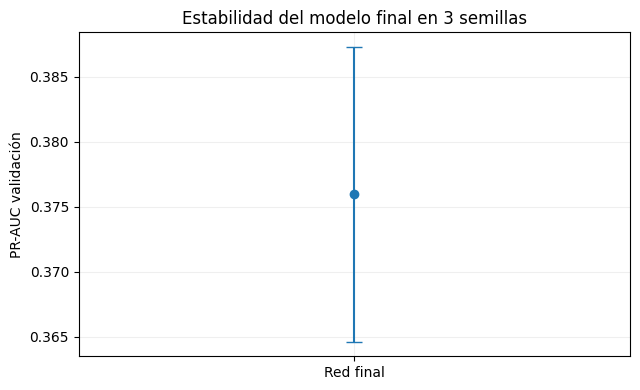

In [22]:
plt.figure(figsize=(6.5, 4))

plt.errorbar(
    ["Red final"],
    [tabla_estabilidad["PR_AUC_val"].mean()],
    yerr=[tabla_estabilidad["PR_AUC_val"].std()],
    fmt="o",
    capsize=6
)

plt.ylabel("PR-AUC validación")
plt.title("Estabilidad del modelo final en 3 semillas")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Evaluación final en test

El conjunto de prueba se utiliza únicamente después de cerrar arquitectura, preprocesamiento y criterio de selección.

In [23]:
prob_log_test = logistica_sin_pv.predict_proba(
    X_test
)[:, 1]

prob_red_test = modelo_final.predict(
    X_test,
    verbose=0
).ravel()

metricas_log_test = calcular_metricas(
    y_test.astype(int),
    prob_log_test,
    umbral=0.5
)

metricas_red_test = calcular_metricas(
    y_test.astype(int),
    prob_red_test,
    umbral=0.5
)

comparacion_test = pd.DataFrame([
    {
        "Modelo": "Regresión logística",
        **metricas_log_test
    },
    {
        "Modelo": "Red neuronal final",
        **metricas_red_test
    }
])

display(comparacion_test.round(4))

,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Regresión logística,0.6412,0.2594,0.6993,0.3784,0.7354,0.3091
1,Red neuronal final,0.6827,0.2872,0.6958,0.4065,0.7690,0.3451


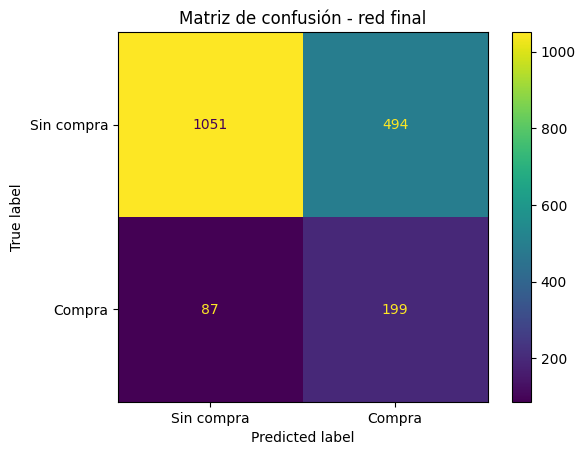

In [24]:
pred_red_test = (
    prob_red_test >= 0.5
).astype(int)

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test.astype(int),
        pred_red_test
    ),
    display_labels=[
        "Sin compra",
        "Compra"
    ]
).plot()

plt.title(
    "Matriz de confusión - red final"
)
plt.show()

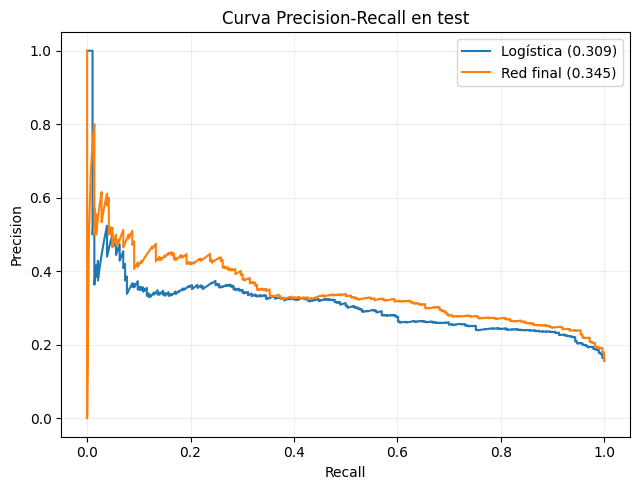

In [25]:
precision_red, recall_red, _ = precision_recall_curve(
    y_test.astype(int),
    prob_red_test
)

precision_log, recall_log, _ = precision_recall_curve(
    y_test.astype(int),
    prob_log_test
)

plt.figure(figsize=(6.5, 5))

plt.plot(
    recall_log,
    precision_log,
    label=f"Logística ({metricas_log_test['PR_AUC']:.3f})"
)

plt.plot(
    recall_red,
    precision_red,
    label=f"Red final ({metricas_red_test['PR_AUC']:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall en test")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 13. Comparación final del proyecto

In [26]:
resumen_final = pd.DataFrame([
    {
        "Etapa": "Baseline logístico",
        "PR_AUC_val": metricas_log_sin_val["PR_AUC"],
        "F1_val": metricas_log_sin_val["F1"],
        "Recall_val": metricas_log_sin_val["Recall"]
    },
    {
        "Etapa": "Red base 32-16",
        "PR_AUC_val": metricas_base_val["PR_AUC"],
        "F1_val": metricas_base_val["F1"],
        "Recall_val": metricas_base_val["Recall"]
    },
    {
        "Etapa": "Red final 64-32 + Dropout",
        "PR_AUC_val": metricas_final_val["PR_AUC"],
        "F1_val": metricas_final_val["F1"],
        "Recall_val": metricas_final_val["Recall"]
    }
])

display(resumen_final.round(4))

,Etapa,PR_AUC_val,F1_val,Recall_val
0,Baseline logístico,0.3361,0.3851,0.7028
1,Red base 32-16,0.3582,0.4208,0.7063
2,Red final 64-32 + Dropout,0.3861,0.4159,0.6958


## 14. Guardado del pipeline final

In [27]:
modelo_final.save(
    "modelo_final_compra.keras"
)

joblib.dump(
    preprocesador_final,
    "preprocesador_final.joblib"
)

metadata = {
    "columnas_modelo": columnas_modelo,
    "categorias": categorias,
    "mapa_raras": mapa_raras,
    "umbral": 0.5,
    "arquitectura": "58-64-32-1",
    "dropout": 0.15,
    "optimizador": "Adam",
    "learning_rate": 0.001,
    "batch_size": 32
}

with open(
    "metadata_modelo.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Artefactos guardados:")
print("- modelo_final_compra.keras")
print("- preprocesador_final.joblib")
print("- metadata_modelo.json")

Artefactos guardados:
- modelo_final_compra.keras
- preprocesador_final.joblib
- metadata_modelo.json


## 15. Función de inferencia

In [28]:
def predecir_sesiones(nuevos_datos):
    datos = nuevos_datos.copy()

    for columna in categorias:
        datos[columna] = (
            datos[columna]
            .astype(str)
        )

    for columna, raras in mapa_raras.items():
        datos[columna] = datos[columna].where(
            ~datos[columna].isin(raras),
            "OTRA"
        )

    X_nuevo = preprocesador_final.transform(
        datos[columnas_modelo]
    ).astype("float32")

    probabilidad = modelo_final.predict(
        X_nuevo,
        verbose=0
    ).ravel()

    return pd.DataFrame({
        "probabilidad_compra": probabilidad,
        "prediccion": (
            probabilidad >= 0.5
        ).astype(int)
    })

In [29]:
# Prueba técnica con cinco sesiones del conjunto de prueba
ejemplo = test_df.head(5).copy()
display(
    predecir_sesiones(ejemplo)
)

,probabilidad_compra,prediccion
0,0.875620,1
1,0.357165,0
2,0.001775,0
3,0.765190,1
4,0.000203,0


## 16. Exportación de evidencia

In [30]:
comparacion_pagevalues.to_csv(
    "comparacion_pagevalues.csv",
    index=False
)

comparacion_validacion.to_csv(
    "comparacion_validacion.csv",
    index=False
)

tabla_estabilidad.to_csv(
    "estabilidad_semillas.csv",
    index=False
)

comparacion_test.to_csv(
    "comparacion_test.csv",
    index=False
)

resumen_final.to_csv(
    "resumen_evolucion_modelo.csv",
    index=False
)

print("CSV exportados correctamente.")

CSV exportados correctamente.


## 17. Cierre

El notebook deja reproducible la evolución completa del proyecto: desde la auditoría inicial y el baseline hasta el modelo neuronal final y su validación de estabilidad. El conjunto de prueba no se utiliza para seleccionar configuraciones y el pipeline final conserva las mismas transformaciones definidas con entrenamiento.